In [1]:
import os
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Konfigurasi perangkat (GPU CUDA jika tersedia, fallback ke CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Pustaka PyTorch {torch.__version__} berhasil dimuat. Perangkat komputasi: {device}")

Pustaka PyTorch 2.15.0+cpu berhasil dimuat. Perangkat komputasi: cpu


In [2]:
# Memuat data ulasan dan aspek
path_reviews = '../outputs/reviews_preprocessed.csv'
if not os.path.exists(path_reviews): path_reviews = '../dataset/reviews.csv'
path_aspects = '../dataset/aspect_sentiments.csv'

df_reviews = pd.read_csv(path_reviews)
df_aspects = pd.read_csv(path_aspects)

if 'cleaned_text' not in df_reviews.columns:
    df_reviews['cleaned_text'] = df_reviews['text'].str.lower().str.replace(r'[^a-zA-Z\s]', ' ', regex=True).str.strip()

df_data = pd.merge(df_aspects[['review_id', 'sentiment']], df_reviews[['id', 'cleaned_text']], left_on='review_id', right_on='id')
df_data = df_data[df_data['cleaned_text'].str.len() > 3].drop_duplicates(subset=['id', 'sentiment']).reset_index(drop=True)

# Membangun kamus kosakata (Vocabulary)
kata_freq = {}
for teks in df_data['cleaned_text']:
    for w in teks.split():
        kata_freq[w] = kata_freq.get(w, 0) + 1

# Ambil 1500 kata teratas
vocab = {'<PAD>': 0, '<UNK>': 1}
for w, _ in sorted(kata_freq.items(), key=lambda x: x[1], reverse=True)[:1500]:
    vocab[w] = len(vocab)

# Mapping teks ke sekuens integer ter-padding (panjang maksimal = 35 token)
MAX_LEN = 35
def text_to_sequence(teks):
    tokens = [vocab.get(w, vocab['<UNK>']) for w in teks.split()][:MAX_LEN]
    tokens += [vocab['<PAD>']] * (MAX_LEN - len(tokens))
    return tokens

df_data['sequence'] = df_data['cleaned_text'].apply(text_to_sequence)

# Mapping label sentimen ke integer
label_to_id = {'negative': 0, 'neutral': 1, 'positive': 2}
id_to_label = {v: k for k, v in label_to_id.items()}
df_data['label_id'] = df_data['sentiment'].map(label_to_id)

# Pembagian data latih dan uji berstrata
X_seq = np.array(df_data['sequence'].tolist())
y_lbl = np.array(df_data['label_id'].tolist())

X_tr_seq, X_te_seq, y_tr_seq, y_te_seq = train_test_split(
    X_seq, y_lbl, test_size=0.20, random_state=42, stratify=y_lbl
)

print(f"Ukuran Kosakata (Vocab Size) : {len(vocab)} token")
print(f"Panjang Sekuens Token Maksimal : {MAX_LEN}")
print(f"Sampel Latih: {len(X_tr_seq)}, Sampel Uji: {len(X_te_seq)}")

Ukuran Kosakata (Vocab Size) : 1502 token
Panjang Sekuens Token Maksimal : 35
Sampel Latih: 5296, Sampel Uji: 1324


In [3]:
# Dataset kustom PyTorch
class ReviewDataset(Dataset):
    def __init__(self, sequences, labels):
        self.sequences = torch.tensor(sequences, dtype=torch.long)
        self.labels    = torch.tensor(labels, dtype=torch.long)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        return self.sequences[idx], self.labels[idx]

batch_size = 64
train_dataset = ReviewDataset(X_tr_seq, y_tr_seq)
test_dataset  = ReviewDataset(X_te_seq, y_te_seq)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Jumlah batch pelatihan per epoch: {len(train_loader)}")

Jumlah batch pelatihan per epoch: 83


In [4]:
# Definisi Model 1D-CNN
class TextCNN(nn.Module):
    def __init__(self, vocab_size, embed_dim, num_filters, kernel_size, num_classes, dropout_rate=0.3):
        super(TextCNN, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.conv = nn.Conv1d(in_channels=embed_dim, out_channels=num_filters, kernel_size=kernel_size)
        self.relu = nn.ReLU()
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.dropout = nn.Dropout(dropout_rate)
        self.fc = nn.Linear(num_filters, num_classes)
        
    def forward(self, x):
        # x shape: [batch_size, seq_len]
        embeds = self.embedding(x)                 # [batch_size, seq_len, embed_dim]
        embeds = embeds.permute(0, 2, 1)          # [batch_size, embed_dim, seq_len]
        feature_map = self.relu(self.conv(embeds)) # [batch_size, num_filters, seq_len - kernel + 1]
        pooled = self.pool(feature_map).squeeze(2) # [batch_size, num_filters]
        dropped = self.dropout(pooled)
        logits = self.fc(dropped)                 # [batch_size, num_classes]
        return logits

model_cnn = TextCNN(vocab_size=len(vocab), embed_dim=64, num_filters=128, kernel_size=3, num_classes=3).to(device)
print(model_cnn)

TextCNN(
  (embedding): Embedding(1502, 64, padding_idx=0)
  (conv): Conv1d(64, 128, kernel_size=(3,), stride=(1,))
  (relu): ReLU()
  (pool): AdaptiveMaxPool1d(output_size=1)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=3, bias=True)
)


Epoch [1/8] - Loss: 0.7371
Epoch [2/8] - Loss: 0.6011
Epoch [3/8] - Loss: 0.5602
Epoch [4/8] - Loss: 0.5253
Epoch [5/8] - Loss: 0.5020
Epoch [6/8] - Loss: 0.4925
Epoch [7/8] - Loss: 0.4697
Epoch [8/8] - Loss: 0.4558


<string>:33: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



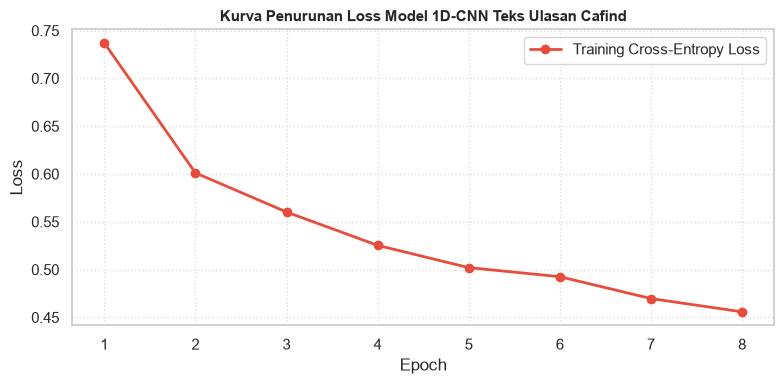

In [5]:
# Konfigurasi loss, optimizer, dan pelatihan
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_cnn.parameters(), lr=0.002, weight_decay=1e-4)
epochs = 8

train_losses = []

for ep in range(epochs):
    model_cnn.train()
    total_loss = 0.0
    for seqs, labels in train_loader:
        seqs, labels = seqs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model_cnn(seqs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * seqs.size(0)
    
    avg_loss = total_loss / len(train_loader.dataset)
    train_losses.append(avg_loss)
    print(f"Epoch [{ep+1}/{epochs}] - Loss: {avg_loss:.4f}")

# Visualisasi kurva loss pelatihan
plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs+1), train_losses, marker='o', color='#e74c3c', linewidth=2, label='Training Cross-Entropy Loss')
plt.title('Kurva Penurunan Loss Model 1D-CNN Teks Ulasan Cafind', fontsize=11, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

Akurasi Pengujian 1D-CNN: 73.94%

Classification Report 1D-CNN:
              precision    recall  f1-score   support

    negative     0.4118    0.2188    0.2857        64
     neutral     0.6633    0.5919    0.6256       446
    positive     0.7859    0.8612    0.8218       814

    accuracy                         0.7394      1324
   macro avg     0.6203    0.5573    0.5777      1324
weighted avg     0.7265    0.7394    0.7298      1324



<string>:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



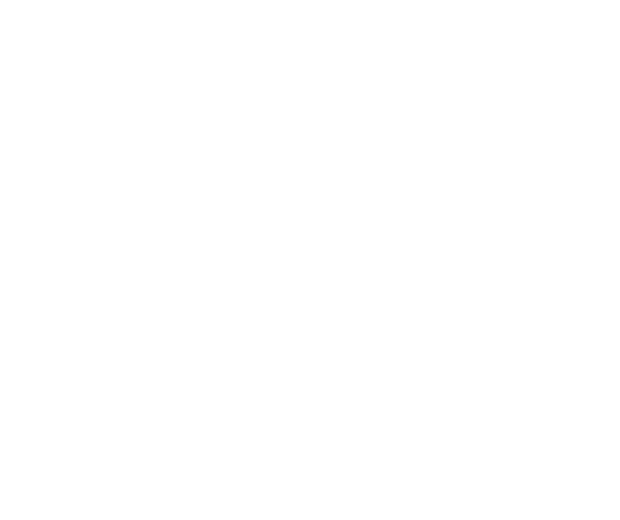

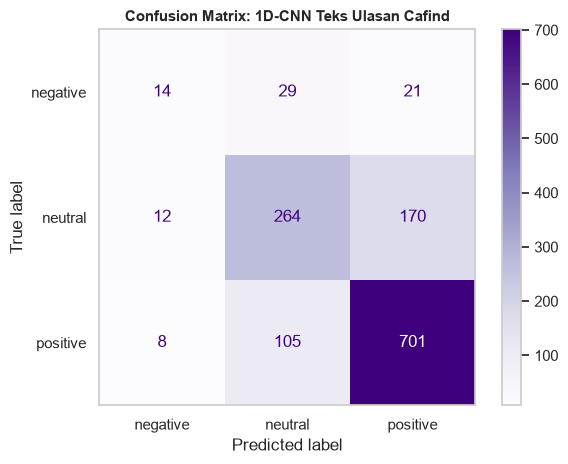

In [6]:
# Evaluasi data uji
model_cnn.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for seqs, labels in test_loader:
        seqs = seqs.to(device)
        outputs = model_cnn(seqs)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(labels.numpy())

acc_cnn = accuracy_score(all_targets, all_preds)
target_names = [id_to_label[i] for i in range(3)]

print(f"Akurasi Pengujian 1D-CNN: {acc_cnn*100:.2f}%")
print("\nClassification Report 1D-CNN:")
print(classification_report(all_targets, all_preds, target_names=target_names, digits=4))

# Visualisasi Matriks Konfusi
cm_cnn = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_cnn, display_labels=target_names)
disp.plot(cmap='Purples', values_format='d')
plt.title('Confusion Matrix: 1D-CNN Teks Ulasan Cafind', fontsize=11, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

In [7]:
# Menyimpan model PyTorch dan kamus vocab
os.makedirs('../outputs', exist_ok=True)
path_saved_cnn = '../outputs/text_cnn_model_js14.pt'
torch.save({
    'model_state_dict': model_cnn.state_dict(),
    'vocab': vocab,
    'max_len': MAX_LEN,
    'label_map': label_to_id
}, path_saved_cnn)

print(f"Model 1D-CNN berhasil disimpan ke: {path_saved_cnn}")

Model 1D-CNN berhasil disimpan ke: ../outputs/text_cnn_model_js14.pt
